In [37]:
# ============================================================
#  SETUP   (run me first)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

import ipywidgets as widgets
from IPython.display import display

# --- detect Google Colab --------------------------------------
# NOTE: deliberately NOT calling output.enable_custom_widget_manager().
# That switch exists for THIRD-PARTY custom widgets (plotly FigureWidget,
# ipycanvas, ipycytoscape, anywidget ...) and makes Colab fetch the widget
# JavaScript from a CDN. The sliders in this notebook are standard
# ipywidgets (FloatSlider, Tab, ToggleButtons, Checkbox), which Colab
# supports natively - so enabling it would only add a way for the panel
# to come up blank.
try:
    import google.colab          # noqa: F401
    _IN_COLAB = True
except Exception:
    _IN_COLAB = False

%matplotlib inline
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'legend.framealpha': 0.9,
    'axes.axisbelow': True,
})

print('Running in Google Colab :', _IN_COLAB)
print('numpy', np.__version__, '| pandas', pd.__version__,
      '| matplotlib', plt.matplotlib.__version__,
      '| ipywidgets', widgets.__version__)
print('Setup complete.')

Running in Google Colab : True
numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | ipywidgets 7.7.1
Setup complete.


In [38]:
# ============================================================
#  SIMULATION ENGINE  --  DC motor + P / PD / PI / PID control
#  (run this cell once; every other cell uses these functions)
# ============================================================
import numpy as np
from scipy.integrate import solve_ivp

# ------------------------------------------------------------
# Nominal motor parameters (standard CTMS / textbook DC motor)
# ------------------------------------------------------------
MOTOR = {
    'J': 0.01,   # rotor moment of inertia          [kg.m^2]
    'b': 0.1,    # viscous friction coefficient     [N.m.s]
    'K': 0.01,   # torque const = back-emf const    [N.m/A = V.s/rad]
    'R': 1.0,    # armature resistance              [Ohm]
    'L': 0.5,    # armature inductance              [H]
}

# Design gains used for the final P vs PD vs PI vs PID comparison
DESIGN_GAINS = {'Kp': 100.0, 'Ki': 80.0, 'Kd': 5.0}

CONTROLLERS = ['P', 'PD', 'PI', 'PID']
COLORS = {'P': '#d62728', 'PD': '#ff7f0e', 'PI': '#2ca02c', 'PID': '#1f77b4'}


# ------------------------------------------------------------
# 1. Transfer functions of the open-loop motor
# ------------------------------------------------------------
def motor_transfer_functions(L=None, motor=MOTOR):
    # Returns (num, den) polynomial coefficient arrays for the three outputs.
    #   Omega(s)/V(s) = K / [(Js+b)(Ls+R) + K^2]
    #   Theta(s)/V(s) = K / { s*[(Js+b)(Ls+R) + K^2] }
    #       I(s)/V(s) = (Js+b) / [(Js+b)(Ls+R) + K^2]
    J, b, K, R = motor['J'], motor['b'], motor['K'], motor['R']
    L = motor['L'] if L is None else float(L)
    den = np.polyadd(np.polymul([J, b], [L, R]), [K ** 2])
    return {
        'omega':   (np.array([K], dtype=float), den),
        'theta':   (np.array([K], dtype=float), np.polymul([1.0, 0.0], den)),
        'current': (np.array([J, b], dtype=float), den),
    }


def _poly_str(coeffs, var='s'):
    c = np.atleast_1d(np.asarray(coeffs, dtype=float))
    n = len(c) - 1
    terms = []
    for k, a in enumerate(c):
        p = n - k
        if abs(a) < 1e-14:
            continue
        unit = abs(abs(a) - 1.0) < 1e-12
        mag = '{:.5g}'.format(abs(a))
        if p == 0:
            t = mag
        elif p == 1:
            t = var if unit else '{} {}'.format(mag, var)
        else:
            t = '{}^{}'.format(var, p) if unit else '{} {}^{}'.format(mag, var, p)
        terms.append(('-' if a < 0 else '+', t))
    if not terms:
        return '0'
    out = ('-' + terms[0][1]) if terms[0][0] == '-' else terms[0][1]
    for sign, t in terms[1:]:
        out += ' {} {}'.format(sign, t)
    return out


def print_transfer_functions(L=None, motor=MOTOR):
    J, b, K, R = motor['J'], motor['b'], motor['K'], motor['R']
    Lv = motor['L'] if L is None else float(L)
    tfs = motor_transfer_functions(Lv, motor)
    print('Motor parameters :  J = {}  b = {}  K = Kt = Ke = {}  R = {}  L = {}'
          .format(J, b, K, R, Lv))
    print('-' * 68)
    labels = {'omega': 'Omega(s) / V(s)   [angular velocity]',
              'theta': 'Theta(s) / V(s)   [angular position]',
              'current': '    I(s) / V(s)   [armature current]'}
    for key in ['omega', 'theta', 'current']:
        num, den = tfs[key]
        ns, ds = _poly_str(num), _poly_str(den)
        width = max(len(ns), len(ds))
        pad = ' ' * 22
        print(labels[key])
        print(pad + ns.center(width))
        print(pad + '-' * width)
        print(pad + ds.center(width))
        print()
    den = tfs['omega'][1]
    poles = np.roots(den)
    print('Open-loop poles (speed)        : ' +
          ', '.join('{:+.4f}'.format(p) if abs(p.imag) < 1e-12
                    else '{:+.4f}{:+.4f}j'.format(p.real, p.imag) for p in poles))
    print('Open-loop DC gain  K/(bR + K^2): {:.5f} (rad/s per volt)'
          .format(K / (b * R + K ** 2)))


# ------------------------------------------------------------
# 2. Closed-loop simulation
# ------------------------------------------------------------
def controller_gains(kind, Kp, Ki, Kd):
    # Masks the gains that a given classical controller does not possess.
    table = {'P':   (Kp, 0.0, 0.0),
             'PD':  (Kp, 0.0, Kd),
             'PI':  (Kp, Ki, 0.0),
             'PID': (Kp, Ki, Kd)}
    return table[str(kind).upper()]


def simulate(Kp=0.0, Ki=0.0, Kd=0.0, L=0.5, ref=1.0, t_end=2.0,
             Vmax=None, Tf=0.0, d_on_error=False, motor=MOTOR, n_points=3000):
    # State vector x = [theta, omega, i, integral_of_error, z]
    #   dtheta/dt = omega
    #   domega/dt = (K*i - b*omega) / J
    #       di/dt = (V - R*i - K*omega) / L
    #       dz/dt = (omega - z) / Tf          <- derivative-filter state
    #
    # Control law, derivative acting on the MEASUREMENT (no derivative kick):
    #       V = Kp*e + Ki*int(e) - D(t),     e = ref - omega
    #
    #   Tf = 0  : ideal derivative,     D = Kd * domega/dt
    #   Tf > 0  : filtered derivative,  D = Kd*(omega - z)/Tf,
    #             which is exactly  Kd*s/(1 + Tf*s)  acting on omega,
    #             the form every real PID uses so that measurement noise
    #             is not amplified without bound.
    J, b, K, R = motor['J'], motor['b'], motor['K'], motor['R']
    L = max(float(L), 1e-4)
    Kp, Ki, Kd = float(Kp), float(Ki), float(Kd)
    Tf = max(float(Tf), 0.0)
    ref, t_end = float(ref), float(t_end)
    filtered = Tf > 1e-6

    def d_contribution(e, omega, cur, z):
        # value ADDED to V by the derivative term
        if d_on_error:
            if filtered:
                return Kd * (e - z) / Tf          # +Kd * de/dt, filtered
            return -Kd * (K * cur - b * omega) / J  # de/dt = -domega/dt, t > 0
        if filtered:
            return -Kd * (omega - z) / Tf         # -Kd * domega/dt, filtered
        return -Kd * (K * cur - b * omega) / J

    def rhs(t, x):
        _, omega, cur, eint, z = x
        e = ref - omega
        dom = (K * cur - b * omega) / J
        V_un = Kp * e + Ki * eint + d_contribution(e, omega, cur, z)
        if Vmax is None:
            V, dei = V_un, e
        else:
            V = float(np.clip(V_un, -Vmax, Vmax))
            # conditional-integration anti-windup
            dei = 0.0 if (V != V_un and e * V_un > 0.0) else e
        dcur = (V - R * cur - K * omega) / L
        if not filtered:
            dz = 0.0
        elif d_on_error:
            dz = (e - z) / Tf
        else:
            dz = (omega - z) / Tf
        return [omega, dom, dcur, dei, dz]

    # Derivative on the ERROR with an ideal differentiator: the step in the
    # reference is differentiated into an impulse of area Kd*ref in V. Passing
    # that impulse through the inductor leaves the current at Kd*ref/L the
    # instant the step is applied - the classic 'derivative kick'.
    i0 = (Kd * ref / L) if (d_on_error and not filtered and abs(Kd) > 1e-12) else 0.0

    t_eval = np.linspace(0.0, t_end, int(n_points))
    try:
        sol = solve_ivp(rhs, (0.0, t_end), [0.0, 0.0, i0, 0.0, 0.0],
                        t_eval=t_eval, method='LSODA',
                        rtol=1e-8, atol=1e-10)
        t = sol.t
        theta, omega, cur, eint, z = sol.y
        ok = bool(sol.success) and len(t) == len(t_eval)
    except Exception:
        t = np.array([0.0])
        theta = omega = cur = eint = z = np.array([0.0])
        ok = False

    e = ref - omega
    V_un = Kp * e + Ki * eint + d_contribution(e, omega, cur, z)
    V = V_un if Vmax is None else np.clip(V_un, -Vmax, Vmax)

    return {'t': t, 'theta': theta, 'omega': omega, 'current': cur,
            'V': V, 'ref': ref, 'ok': ok, 'gains': (Kp, Ki, Kd),
            'Tf': Tf, 'L': L, 'd_on_error': d_on_error,
            'motor': dict(motor),
            'stability': stability_report(Kp, Ki, Kd, Tf, L, motor)}



# ------------------------------------------------------------
# 2b. Controller transfer function, closed-loop poles, stability
# ------------------------------------------------------------
def controller_tf(Kp, Ki, Kd, Tf=0.0):
    # C(s) = Kp + Ki/s + Kd*s/(1 + Tf*s)   returned as (num, den).
    # The Ki = 0 branch drops the free integrator instead of leaving a
    # pole and a zero at the origin to cancel each other numerically.
    Kp, Ki, Kd = float(Kp), float(Ki), float(Kd)
    Tf = max(float(Tf), 0.0)
    has_I = abs(Ki) > 1e-12
    has_f = Tf > 1e-12
    if has_I and has_f:
        num, den = [Kp * Tf + Kd, Kp + Ki * Tf, Ki], [Tf, 1.0, 0.0]
    elif has_I:
        num, den = [Kd, Kp, Ki], [1.0, 0.0]
    elif has_f:
        num, den = [Kp * Tf + Kd, Kp], [Tf, 1.0]
    else:
        num, den = ([Kd, Kp] if abs(Kd) > 1e-12 else [Kp]), [1.0]
    return np.array(num, dtype=float), np.array(den, dtype=float)


def closed_loop_poles(Kp, Ki, Kd, Tf=0.0, L=None, motor=MOTOR):
    # Roots of  den_C(s)*Delta(s) + K*num_C(s) = 0
    J, b, K, R = motor['J'], motor['b'], motor['K'], motor['R']
    Lv = motor['L'] if L is None else float(L)
    delta = np.polyadd(np.polymul([J, b], [Lv, R]), [K ** 2])
    num_c, den_c = controller_tf(Kp, Ki, Kd, Tf)
    char = np.polyadd(np.polymul(den_c, delta), K * num_c)
    char = np.trim_zeros(np.atleast_1d(char), 'f')
    if char.size < 2:
        return np.array([], dtype=complex)
    return np.roots(char)


def stability_report(Kp, Ki, Kd, Tf=0.0, L=None, motor=MOTOR):
    poles = closed_loop_poles(Kp, Ki, Kd, Tf, L, motor)
    if poles.size == 0:
        return {'poles': poles, 'stable': None, 'rightmost': np.nan,
                'verdict': 'NO CLOSED LOOP  -  all gains are zero'}
    rightmost = float(np.max(poles.real))
    if rightmost < -1e-9:
        verdict = ('STABLE  -  every closed-loop pole lies in the left half-plane '
                   '(rightmost Re = {:+.3f})'.format(rightmost))
        stable = True
    elif rightmost > 1e-9:
        verdict = ('UNSTABLE  -  at least one closed-loop pole is in the right '
                   'half-plane (rightmost Re = {:+.3f})'.format(rightmost))
        stable = False
    else:
        verdict = ('MARGINALLY STABLE  -  a pole sits on the imaginary axis '
                   '(rightmost Re = {:+.3f})'.format(rightmost))
        stable = False
    return {'poles': poles, 'stable': stable,
            'rightmost': rightmost, 'verdict': verdict}


def format_poles(poles, nmax=6):
    out = []
    for p in poles[:nmax]:
        if abs(p.imag) < 1e-9:
            out.append('{:+.3f}'.format(p.real))
        else:
            out.append('{:+.3f}{:+.3f}j'.format(p.real, p.imag))
    return ', '.join(out)


# ------------------------------------------------------------
# 3. Step-response performance metrics
# ------------------------------------------------------------
def step_metrics(t, y, ref):
    # Rise time   : 10 % -> 90 % of the final value
    # Settling    : last instant the response leaves a +/-2 % band
    # Overshoot   : peak relative to the final value
    # ss error    : reference - final value
    out = {'Rise time (s)': np.nan, 'Peak time (s)': np.nan,
           'Overshoot (%)': np.nan, 'Settling time (s)': np.nan,
           'Final value': np.nan, 'Steady-state error': np.nan,
           '|SS error| (%)': np.nan}
    t = np.asarray(t, dtype=float)
    y = np.asarray(y, dtype=float)
    if t.size < 5 or not np.all(np.isfinite(y)):
        return out

    yf = float(y[-1])
    out['Final value'] = yf
    out['Steady-state error'] = ref - yf
    if abs(ref) > 1e-12:
        out['|SS error| (%)'] = abs(ref - yf) / abs(ref) * 100.0
    if abs(yf) < 1e-9:
        return out

    i10 = np.where(y >= 0.1 * yf)[0]
    i90 = np.where(y >= 0.9 * yf)[0]
    if i10.size and i90.size:
        out['Rise time (s)'] = float(t[i90[0]] - t[i10[0]])

    pk = int(np.argmax(y))
    out['Peak time (s)'] = float(t[pk])
    out['Overshoot (%)'] = float(max(0.0, (y[pk] - yf) / abs(yf) * 100.0))

    outside = np.where(np.abs(y - yf) > 0.02 * abs(yf))[0]
    if outside.size == 0:
        out['Settling time (s)'] = 0.0
    elif outside[-1] + 1 < t.size:
        out['Settling time (s)'] = float(t[outside[-1] + 1])
    else:
        out['Settling time (s)'] = np.nan      # never settled inside the window
    return out


def theoretical_steady_state(Kp, Ki, ref, motor=MOTOR):
    # Final-value theorem applied to the closed loop.
    #   plant DC gain              : Kdc = K / (b*R + K^2)   [rad/s per volt]
    #   with integral action       : omega_ss = ref exactly, e_ss = 0
    #   without integral action    : omega_ss = ref * Kp*Kdc / (1 + Kp*Kdc)
    # At steady state the motor torque balances friction, so  i_ss = b*omega_ss / K
    Kdc = motor['K'] / (motor['b'] * motor['R'] + motor['K'] ** 2)
    if abs(Ki) > 1e-12:
        w_ss = float(ref)
    else:
        w_ss = float(ref) * Kp * Kdc / (1.0 + Kp * Kdc)
    i_ss = motor['b'] * w_ss / motor['K']
    return {'omega_ss': w_ss, 'e_ss': float(ref) - w_ss,
            'i_ss': i_ss, 'Kdc': Kdc}


def run_all_controllers(Kp, Ki, Kd, L, ref, t_end, Vmax=None, Tf=0.0,
                        d_on_error=False, motor=MOTOR):
    # Simulates P, PD, PI and PID with the same Kp/Ki/Kd set.
    results = {}
    for name in CONTROLLERS:
        kp, ki, kd = controller_gains(name, Kp, Ki, Kd)
        results[name] = simulate(kp, ki, kd, L, ref, t_end, Vmax=Vmax, Tf=Tf,
                                 d_on_error=d_on_error, motor=motor)
    return results

In [39]:
# ============================================================
#  PLOTTING
#  3 state variables:  omega (speed) | theta (position) | i (current)
#  plus the control effort V(t), with the standard step-response
#  measurements marked directly on the curves.
# ============================================================
STATE_INFO = [
    ('omega',   'State 1 : Angular velocity  $\\omega(t)$', 'Speed  [rad/s]'),
    ('theta',   'State 2 : Angular position  $\\theta(t)$', 'Position  [rad]'),
    ('current', 'State 3 : Armature current  $i(t)$',       'Current  [A]'),
]

_NOTE = dict(fontsize=8.2, zorder=6,
             bbox=dict(boxstyle='round,pad=0.28', fc='white', alpha=0.88))


def _tag(ax, x, y, text, color, ha='left', va='bottom', dx=0.0, dy=0.0):
    ax.annotate(text, xy=(x, y), xytext=(x + dx, y + dy), ha=ha, va=va,
                color=color, **dict(_NOTE, bbox=dict(boxstyle='round,pad=0.28',
                                                     fc='white', ec=color, alpha=0.88)))



def _headroom(ax, top=0.28, bottom=0.10):
    # Make room above/below the data so annotation boxes do not collide
    # with the title or run off the axes.
    lo, hi = ax.get_ylim()
    span = hi - lo
    if span <= 0:
        return
    ax.set_ylim(lo - bottom * span, hi + top * span)


def metrics_frame(results, ref, Kp, Ki, Kd, motor=None, Tf=0.0):
    # Comparison table of performance metrics for the speed loop.
    rows = []
    for name in CONTROLLERS:
        if name not in results:
            continue
        r = results[name]
        m = step_metrics(r['t'], r['omega'], ref)
        kp, ki, kd = controller_gains(name, Kp, Ki, Kd)
        th = theoretical_steady_state(kp, ki, ref, motor or MOTOR)
        st = r.get('stability') or stability_report(kp, ki, kd, Tf, r.get('L'),
                                                    motor or MOTOR)
        rows.append({
            'Controller': name,
            'Kp': kp, 'Ki': ki, 'Kd': kd,
            'Rise time tr (s)': m['Rise time (s)'],
            'Peak time tp (s)': m['Peak time (s)'],
            'Settling time ts (s)': m['Settling time (s)'],
            'Overshoot Mp (%)': m['Overshoot (%)'],
            'Final speed (rad/s)': m['Final value'],
            'ess simulated': m['Steady-state error'],
            'ess theoretical': th['e_ss'],
            'Peak current (A)': float(np.max(np.abs(r['current']))) if r['t'].size > 1 else np.nan,
            'Peak voltage (V)': float(np.max(np.abs(r['V']))) if r['t'].size > 1 else np.nan,
            'Stability': ('STABLE' if st['stable'] else
                          ('UNSTABLE' if st['stable'] is False else '-')),
        })
    return pd.DataFrame(rows).set_index('Controller')


def _annotate_speed(ax, t, y, ref, m, col):
    # rise time, peak / overshoot, settling time and steady-state error
    yf = m['Final value']
    if not np.isfinite(yf) or abs(yf) < 1e-9:
        return
    if np.isfinite(m['Rise time (s)']):
        i10 = np.where(y >= 0.1 * yf)[0]
        i90 = np.where(y >= 0.9 * yf)[0]
        if i10.size and i90.size:
            t10, t90 = t[i10[0]], t[i90[0]]
            ax.annotate('', xy=(t10, 0.1 * yf), xytext=(t90, 0.1 * yf),
                        arrowprops=dict(arrowstyle='<->', color='#1f77b4', lw=1.2))
            _tag(ax, t90, 0.1 * yf, '$t_r$ = {:.4f} s'.format(m['Rise time (s)']),
                 '#1f77b4', dx=0.02 * t[-1], dy=-0.03 * yf)
    if np.isfinite(m['Peak time (s)']):
        tp = m['Peak time (s)']
        yp = float(np.max(y))
        ax.plot([tp], [yp], marker='v', ms=6, color='#b03030', zorder=6)
        lo, hi = ax.get_ylim()
        near_top = (hi - yp) < 0.22 * (hi - lo)
        _tag(ax, tp, yp, '$M_p$ = {:.2f} %\npeak {:.4f} @ {:.3f} s'
             .format(m['Overshoot (%)'], yp, tp), '#b03030',
             va=('top' if near_top else 'bottom'),
             dx=0.03 * t[-1],
             dy=(-0.04 if near_top else 0.03) * (hi - lo))
    ts = m['Settling time (s)']
    if np.isfinite(ts) and ts > 0:
        ax.axvline(ts, color='#e07b00', ls='--', lw=1.1, zorder=2)
        _tag(ax, ts, 0.42 * yf, '$t_s$ (2 %) = {:.4f} s'.format(ts),
             '#e07b00', dx=0.02 * t[-1])
    ess = m['Steady-state error']
    _tag(ax, t[-1], yf, '$e_{{ss}}$ = {:+.4f} rad/s\n({:.2f} % of ref)'
         .format(ess, 100 * abs(ess) / abs(ref) if ref else np.nan),
         '#555555', ha='right', va='top', dx=-0.01 * t[-1], dy=-0.04 * abs(yf))


def plot_single(controller='PID', Kp=100.0, Ki=80.0, Kd=5.0, L=0.5,
                ref=1.0, t_end=2.0, Vmax=None, Tf=0.0, d_on_error=False,
                motor=None, save_as=None, show=True, verbose=True):
    # One controller: all three state variables plus the control effort.
    motor = motor or MOTOR
    kp, ki, kd = controller_gains(controller, Kp, Ki, Kd)
    r = simulate(kp, ki, kd, L, ref, t_end, Vmax=Vmax, Tf=Tf,
                 d_on_error=d_on_error, motor=motor)
    col = COLORS[controller]
    st = r['stability']

    if not r['ok'] or r['t'].size < 5:
        print('!! The simulation did not complete - the closed loop is diverging.')
        if st['poles'].size:
            print('   Closed-loop poles:', format_poles(st['poles']))
        return r

    m = step_metrics(r['t'], r['omega'], ref)
    th = theoretical_steady_state(kp, ki, ref, motor)

    fig, axes = plt.subplots(2, 2, figsize=(13.2, 8.0))
    head = ('{} controller      Kp = {:.2f}    Ki = {:.2f}    Kd = {:.2f}    Tf = {:.3f} s'
            .format(controller, kp, ki, kd, Tf))
    head += ('\nmotor:  J = {:.4f}   b = {:.4f}   K = {:.4f}   R = {:.3f}   L = {:.3f} H'
             '      derivative on {}'
             .format(motor['J'], motor['b'], motor['K'], motor['R'], L,
                     'error' if d_on_error else 'measurement'))
    fig.suptitle(head, fontsize=11, fontweight='bold', y=0.985)

    band = '#1a7f37' if st['stable'] else '#b03030'
    fig.text(0.5, 0.925, st['verdict'], ha='center', va='center',
             fontsize=9.5, color='white', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.4', fc=band, ec='none'))
    fig.text(0.5, 0.893, 'closed-loop poles:  ' + format_poles(st['poles']),
             ha='center', va='center', fontsize=8.6, color='#444444',
             family='monospace')

    # --- state 1 : angular velocity -----------------------------------
    ax = axes[0, 0]
    ax.axhspan(0.98 * ref, 1.02 * ref, color='#999999', alpha=0.16, zorder=1)
    ax.axhline(ref, color='k', ls='--', lw=1.1, zorder=3)
    ax.plot(r['t'], r['omega'], color=col, lw=2.1, zorder=4)
    _headroom(ax, top=0.34, bottom=0.12)
    _annotate_speed(ax, r['t'], r['omega'], ref, m, col)
    ax.set_title(STATE_INFO[0][1] + '   -   the controlled variable', fontsize=10.5)
    ax.set_ylabel(STATE_INFO[0][2]); ax.set_xlabel('Time  [s]')
    ax.grid(alpha=0.3)

    # --- state 2 : angular position -----------------------------------
    ax = axes[0, 1]
    ax.plot(r['t'], r['theta'], color=col, lw=2.1)
    th_end = float(r['theta'][-1])
    _tag(ax, r['t'][-1], th_end, '$\\theta$({:.1f} s) = {:.3f} rad\n({:.3f} rev)'
         .format(t_end, th_end, th_end / (2 * np.pi)), '#555555',
         ha='right', va='top', dx=-0.02 * t_end)
    _headroom(ax, top=0.26, bottom=0.08)
    ax.set_title(STATE_INFO[1][1] + '   -   ramps while the motor turns', fontsize=10.5)
    ax.set_ylabel(STATE_INFO[1][2]); ax.set_xlabel('Time  [s]')
    ax.grid(alpha=0.3)

    # --- state 3 : armature current -----------------------------------
    ax = axes[1, 0]
    ax.plot(r['t'], r['current'], color=col, lw=2.1)
    _headroom(ax, top=0.30, bottom=0.26)
    ip = int(np.argmax(np.abs(r['current'])))
    ax.plot([r['t'][ip]], [r['current'][ip]], marker='v', ms=6, color='#b03030')
    _tag(ax, r['t'][ip], r['current'][ip],
         'peak {:.3f} A @ {:.3f} s'.format(r['current'][ip], r['t'][ip]),
         '#b03030', dx=0.03 * t_end)
    ax.axhline(th['i_ss'], color='#555555', ls=':', lw=1.2)
    _tag(ax, r['t'][-1], th['i_ss'],
         '$i_{{ss}} = b\\,\\omega_{{ss}}/K$ = {:.3f} A'.format(th['i_ss']),
         '#555555', ha='right', va='top', dx=-0.02 * t_end)
    ax.set_title(STATE_INFO[2][1] + '   -   proportional to torque', fontsize=10.5)
    ax.set_ylabel(STATE_INFO[2][2]); ax.set_xlabel('Time  [s]')
    ax.grid(alpha=0.3)

    # --- control effort ------------------------------------------------
    ax = axes[1, 1]
    ax.plot(r['t'], r['V'], color='#6a6a6a', lw=1.9)
    _headroom(ax, top=0.26, bottom=0.14)
    if Vmax is not None:
        ax.axhline(Vmax, color='#b03030', ls='--', lw=1.1)
        ax.axhline(-Vmax, color='#b03030', ls='--', lw=1.1)
        _tag(ax, t_end, Vmax, 'saturation $\\pm${:.0f} V'.format(Vmax),
             '#b03030', ha='right', va='bottom', dx=-0.02 * t_end)
    _tag(ax, r['t'][-1], float(r['V'][-1]),
         'peak |V| = {:.2f} V'.format(float(np.max(np.abs(r['V'])))),
         '#555555', ha='right', va='bottom', dx=-0.02 * t_end)
    ax.set_title('Control effort : armature voltage  $V(t)$   -   what the drive must supply',
                 fontsize=10.5)
    ax.set_ylabel('Voltage  [V]'); ax.set_xlabel('Time  [s]')
    ax.grid(alpha=0.3)

    fig.tight_layout(rect=[0, 0, 1, 0.878])
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches='tight', facecolor='white')
    r['fig'] = fig
    if show:
        plt.show()
    if not verbose:
        return r

    print('PERFORMANCE   {} controller,  reference = {:.3f} rad/s'.format(controller, ref))
    print('-' * 68)
    print('  Rise time      tr  (10-90 %)      : {:>10.4f}  s'.format(m['Rise time (s)']))
    print('  Peak time      tp                 : {:>10.4f}  s'.format(m['Peak time (s)']))
    print('  Settling time  ts  (+/-2 %)       : {:>10.4f}  s'.format(m['Settling time (s)']))
    print('  Overshoot      Mp                 : {:>10.3f}  %'.format(m['Overshoot (%)']))
    print('  Final speed                       : {:>10.5f}  rad/s'.format(m['Final value']))
    print('  Steady-state error  (simulated)   : {:>10.5f}  rad/s'.format(m['Steady-state error']))
    print('  Steady-state error  (theoretical) : {:>10.5f}  rad/s'.format(th['e_ss']))
    print('  Peak current / steady current     : {:>10.3f}  A  /{:9.3f} A'
          .format(float(np.max(np.abs(r['current']))), th['i_ss']))
    print('  Peak voltage                      : {:>10.2f}  V'.format(float(np.max(np.abs(r['V'])))))
    print('  Position at t = {:<5.2f} s           : {:>10.4f}  rad  ({:.3f} rev)'
          .format(t_end, th_end, th_end / (2 * np.pi)))
    print('  Closed-loop poles                 : ' + format_poles(st['poles']))
    print('  ' + st['verdict'])
    return r


def plot_comparison(Kp=100.0, Ki=80.0, Kd=5.0, L=0.5, ref=1.0, t_end=2.0,
                    Vmax=None, Tf=0.0, d_on_error=False, motor=None,
                    show_table=True, save_as=None, show=True):
    # P vs PD vs PI vs PID, overlaid for all three state variables.
    motor = motor or MOTOR
    results = run_all_controllers(Kp, Ki, Kd, L, ref, t_end, Vmax=Vmax, Tf=Tf,
                                  d_on_error=d_on_error, motor=motor)

    fig, axes = plt.subplots(3, 1, figsize=(11.5, 12.0), sharex=True)
    head = ('P  vs  PD  vs  PI  vs  PID        Kp = {:.2f}   Ki = {:.2f}   Kd = {:.2f}   Tf = {:.3f} s'
            .format(Kp, Ki, Kd, Tf))
    head += ('\nmotor:  J = {:.4f}   b = {:.4f}   K = {:.4f}   R = {:.3f}   L = {:.3f} H'
             '      derivative on {}'
             .format(motor['J'], motor['b'], motor['K'], motor['R'], L,
                     'error' if d_on_error else 'measurement'))
    fig.suptitle(head, fontsize=11.5, fontweight='bold')

    for ax, (key, title, ylabel) in zip(axes, STATE_INFO):
        for name in CONTROLLERS:
            r = results[name]
            if r['t'].size < 5:
                continue
            kp, ki, kd = controller_gains(name, Kp, Ki, Kd)
            lbl = '{}  (Kp={:.0f}'.format(name, kp)
            lbl += ', Ki={:.0f}'.format(ki) if ki else ''
            lbl += ', Kd={:.1f}'.format(kd) if kd else ''
            lbl += ')'
            if not r['stability']['stable']:
                lbl += '  UNSTABLE'
            ax.plot(r['t'], r[key], color=COLORS[name], lw=2.0, label=lbl)
        if key == 'omega':
            ax.axhspan(0.98 * ref, 1.02 * ref, color='#999999', alpha=0.16)
            ax.axhline(ref, color='k', ls='--', lw=1.1, label='reference')
        ax.set_title(title, fontsize=11)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend(loc='best', fontsize=8.8)
    axes[-1].set_xlabel('Time  [s]')

    fig.tight_layout(rect=[0, 0, 1, 0.955])
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches='tight', facecolor='white')
    results['fig'] = fig
    if show:
        plt.show()
    if show_table:
        display(metrics_frame(results, ref, Kp, Ki, Kd, motor, Tf).round(4))
    return results

In [40]:
# ============================================================
#  GUI BUILDER
#  One factory used by both slider panels, so the controls stay
#  identical and there is only one place to change them.
#
#  Tab 1  Controller : Kp, Ki, Kd, Tf   (controller-specific)
#  Tab 2  Motor      : J, b, K, R, L    (plant parameters)
#  Tab 3  Simulation : reference, duration, voltage saturation
# ============================================================
# Nothing here touches ipywidgets at import time: every control is built
# inside build_panel(), so if the widget front-end is unavailable the
# failure happens at one catchable point instead of breaking this cell.
_STYLE = {'description_width': '120px'}
_WIDTH = '430px'


def _fs(value, lo, hi, step, desc, fmt='.2f', tip=''):
    return widgets.FloatSlider(value=value, min=lo, max=hi, step=step,
                               description=desc, style=_STYLE,
                               layout=widgets.Layout(width=_WIDTH),
                               readout_format=fmt, continuous_update=False,
                               description_tooltip=tip)


def build_panel(with_controller_toggle=True):
    # Returns (controls_dict, panel_widget).
    c = {}

    # ---- tab 1 : controller-specific tunable parameters -------------
    c['Kp'] = _fs(DESIGN_GAINS['Kp'], 0.0, 500.0, 1.0, 'Kp', '.1f',
                  'Proportional gain')
    c['Ki'] = _fs(DESIGN_GAINS['Ki'], 0.0, 1000.0, 5.0, 'Ki', '.1f',
                  'Integral gain - the only term that removes steady-state error')
    c['Kd'] = _fs(DESIGN_GAINS['Kd'], 0.0, 50.0, 0.25, 'Kd', '.2f',
                  'Derivative gain - adds damping, no effect at DC')
    c['Tf'] = _fs(0.0, 0.0, 0.20, 0.002, 'Tf  [s]', '.3f',
                  'Derivative filter time constant. 0 = ideal derivative.')
    c['d_on_error'] = widgets.RadioButtons(
        options=[('on the measurement  (no derivative kick)', False),
                 ('on the error  (classic textbook form)', True)],
        value=False, description='dD/dt acts:', style=_STYLE,
        layout=widgets.Layout(width='470px'))
    tab_ctrl = widgets.VBox([
        c['Kp'], c['Ki'], c['Kd'], c['Tf'], c['d_on_error'],
        widgets.HTML('<i style="color:#666;font-size:90%">'
                     'C(s) = Kp + Ki/s + Kd&middot;s/(1 + Tf&middot;s) &nbsp;&mdash;&nbsp; '
                     'set Tf = 0 for the ideal derivative, Tf &asymp; Kd/(10&middot;Kp) '
                     'for a realistic noise-tolerant one.<br>'
                     'Derivative <b>on the error</b> is the classic textbook PID: it puts '
                     'zeros in the closed-loop numerator and so looks faster, but it '
                     'differentiates the step and slams the current to '
                     'Kd&middot;&omega;<sub>ref</sub>/L at t = 0. Derivative <b>on the '
                     'measurement</b> keeps the same poles without that spike.</i>')])

    # ---- tab 2 : motor (plant) parameters ---------------------------
    c['J'] = _fs(MOTOR['J'], 0.001, 0.100, 0.001, 'J  [kg.m2]', '.3f',
                 'Rotor moment of inertia')
    c['b'] = _fs(MOTOR['b'], 0.010, 0.500, 0.005, 'b  [N.m.s]', '.3f',
                 'Viscous friction coefficient')
    c['K'] = _fs(MOTOR['K'], 0.005, 0.200, 0.005, 'K = Kt = Ke', '.3f',
                 'Torque constant = back-emf constant (SI units)')
    c['R'] = _fs(MOTOR['R'], 0.100, 10.00, 0.100, 'R  [Ohm]', '.2f',
                 'Armature resistance')
    c['L'] = _fs(MOTOR['L'], 0.010, 1.500, 0.010, 'L  [H]', '.3f',
                 'Armature inductance - sets the electrical time constant L/R')
    btn_reset = widgets.Button(description='Reset motor to nominal',
                               button_style='', icon='undo',
                               layout=widgets.Layout(width='220px'))

    def _reset(_):
        for k in ['J', 'b', 'K', 'R', 'L']:
            c[k].value = MOTOR[k]

    btn_reset.on_click(_reset)
    tab_motor = widgets.VBox([
        c['J'], c['b'], c['K'], c['R'], c['L'], btn_reset,
        widgets.HTML('<i style="color:#666;font-size:90%">'
                     'These describe the motor itself, not the controller. '
                     'Electrical time constant L/R, mechanical time constant J/b.</i>')])

    # ---- tab 3 : simulation / operating conditions ------------------
    c['ref'] = _fs(1.0, 0.5, 50.0, 0.5, 'Ref speed [rad/s]', '.1f',
                   'Commanded step in shaft speed')
    c['t_end'] = _fs(2.0, 0.2, 10.0, 0.1, 'Duration [s]', '.1f',
                     'Length of the simulation window')
    c['sat'] = widgets.Checkbox(value=False, description='Limit supply voltage',
                                indent=False, layout=widgets.Layout(width='230px'))
    c['Vmax'] = _fs(48.0, 5.0, 300.0, 1.0, 'V max  [V]', '.0f',
                    'Supply-rail limit, with anti-windup on the integrator')
    c['Vmax'].disabled = True
    c['sat'].observe(lambda ch: setattr(c['Vmax'], 'disabled', not c['sat'].value),
                     names='value')
    tab_sim = widgets.VBox([
        c['ref'], c['t_end'], c['sat'], c['Vmax'],
        widgets.HTML('<i style="color:#666;font-size:90%">'
                     'With saturation on, the drive can no longer deliver whatever '
                     'voltage the controller asks for - which is what happens on real '
                     'hardware.</i>')])

    tabs = widgets.Tab(children=[tab_ctrl, tab_motor, tab_sim])
    for i, t in enumerate(['Controller', 'Motor (plant)', 'Simulation']):
        tabs.set_title(i, t)

    header = []
    if with_controller_toggle:
        c['controller'] = widgets.ToggleButtons(
            options=CONTROLLERS, value='PID', description='Controller:',
            style={'description_width': '120px'},
            tooltips=['Proportional', 'Proportional-Derivative',
                      'Proportional-Integral',
                      'Proportional-Integral-Derivative'])

        def _sync(change=None):
            # grey out the gains the selected controller does not possess
            sel = c['controller'].value
            c['Ki'].disabled = ('I' not in sel)
            c['Kd'].disabled = ('D' not in sel)
            c['Tf'].disabled = ('D' not in sel)
            c['d_on_error'].disabled = ('D' not in sel)

        c['controller'].observe(_sync, names='value')
        _sync()
        header.append(c['controller'])
    else:
        header.append(widgets.HTML(
            '<b>Shared parameters</b> &mdash; every controller receives the same set '
            'and simply ignores the terms it does not have.'))

    panel = widgets.VBox(header + [tabs])
    return c, panel

In [41]:
# ============================================================
#  GUI 1  -  one controller at a time
#  The slider panel below IS the graphical user interface:
#  standard ipywidgets rendered inline by Colab. Three state
#  variables plus the control effort are redrawn on every change.
# ============================================================
def _run_single(controller, Kp, Ki, Kd, Tf, d_on_error, J, b, K, R, L, ref, t_end, sat, Vmax):
    plot_single(controller=controller, Kp=Kp, Ki=Ki, Kd=Kd, Tf=Tf, d_on_error=d_on_error,
                motor={'J': J, 'b': b, 'K': K, 'R': R, 'L': L},
                L=L, ref=ref, t_end=t_end, Vmax=(Vmax if sat else None))


try:
    ctl_1, panel_1 = build_panel(with_controller_toggle=True)
    out_1 = widgets.interactive_output(_run_single, ctl_1)
    display(panel_1, out_1)
    SLIDERS_OK = True
except Exception as _exc:
    SLIDERS_OK = False
    print('Could not build the slider panel ({}: {}).'
          .format(type(_exc).__name__, _exc))
    print('Falling back to a static plot - see the cell at the end of section 5')
    print('to drive the same simulation by typing the numbers in directly.\n')
    plot_single(controller='PID', Kp=DESIGN_GAINS['Kp'], Ki=DESIGN_GAINS['Ki'],
                Kd=DESIGN_GAINS['Kd'], Tf=0.0, L=MOTOR['L'], ref=1.0, t_end=2.0)

Output()

In [42]:
# ============================================================
#  GUI 2  -  P vs PD vs PI vs PID on the same axes
# ============================================================
def _run_compare(Kp, Ki, Kd, Tf, d_on_error, J, b, K, R, L, ref, t_end, sat, Vmax):
    plot_comparison(Kp=Kp, Ki=Ki, Kd=Kd, Tf=Tf, d_on_error=d_on_error,
                    motor={'J': J, 'b': b, 'K': K, 'R': R, 'L': L},
                    L=L, ref=ref, t_end=t_end,
                    Vmax=(Vmax if sat else None), show_table=True)


try:
    ctl_2, panel_2 = build_panel(with_controller_toggle=False)
    out_2 = widgets.interactive_output(_run_compare, ctl_2)
    display(panel_2, out_2)
except Exception as _exc:
    print('Could not build the slider panel ({}: {}).'
          .format(type(_exc).__name__, _exc))
    print('Falling back to a static comparison.\n')
    plot_comparison(Kp=DESIGN_GAINS['Kp'], Ki=DESIGN_GAINS['Ki'],
                    Kd=DESIGN_GAINS['Kd'], Tf=0.0, L=MOTOR['L'],
                    ref=1.0, t_end=2.0, show_table=True)

Output()

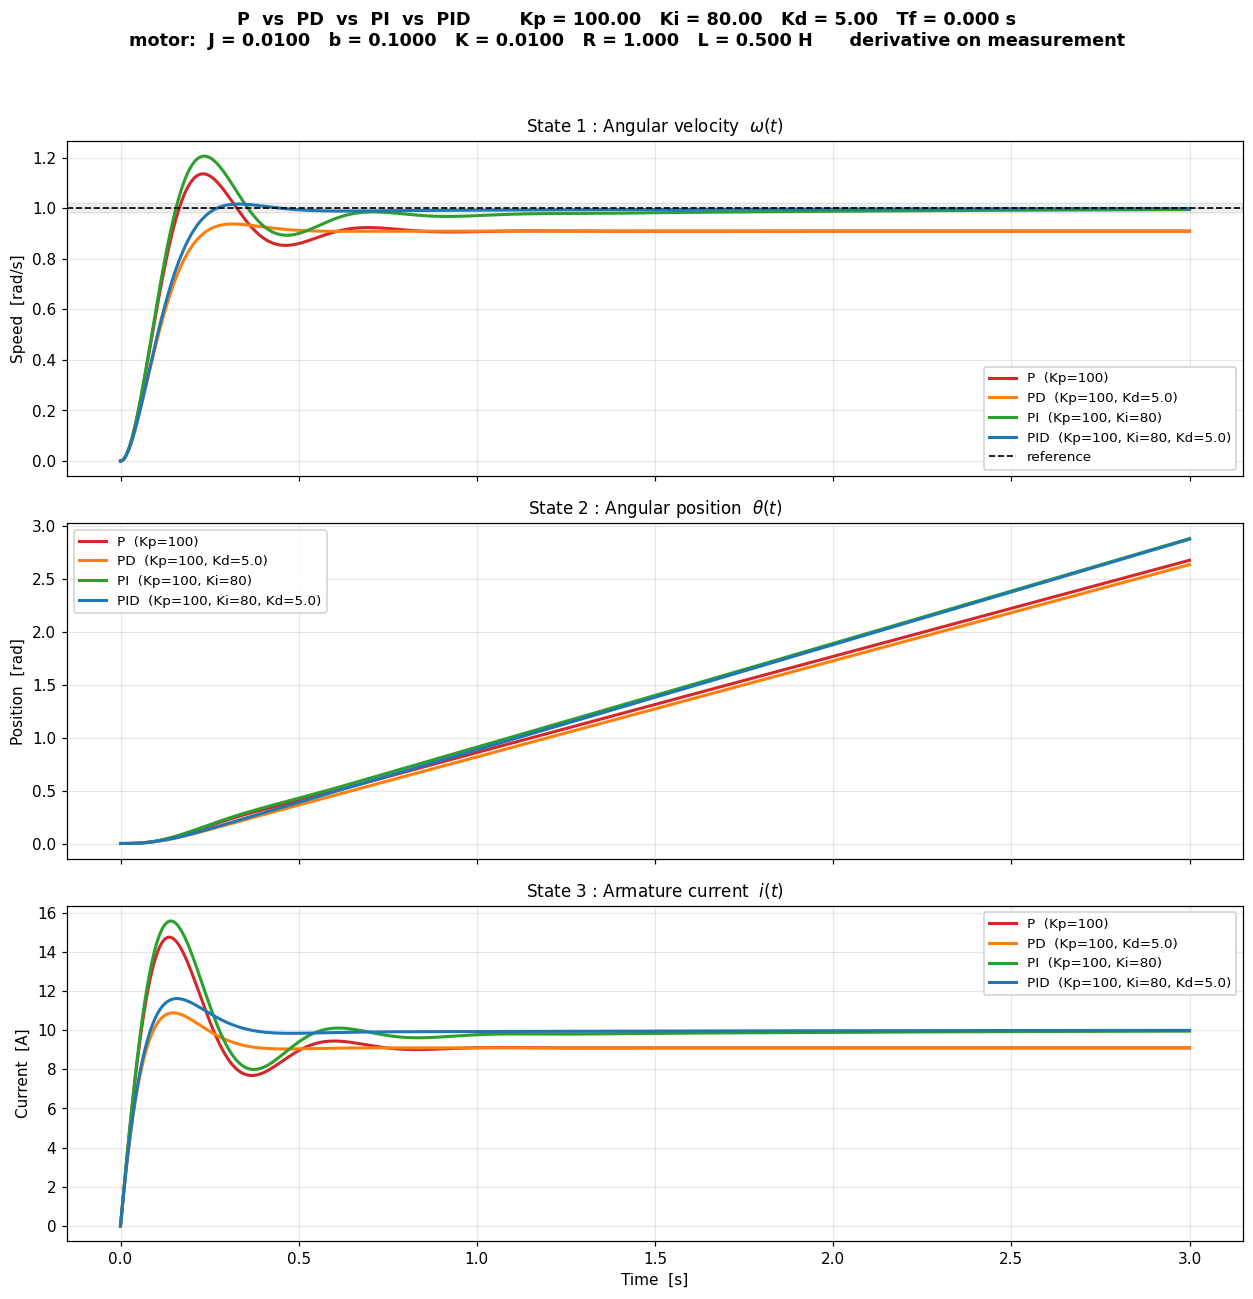

In [43]:
REF = 1.0
TEND = 3.0

final_results = plot_comparison(Kp=DESIGN_GAINS['Kp'],
                                Ki=DESIGN_GAINS['Ki'],
                                Kd=DESIGN_GAINS['Kd'],
                                L=MOTOR['L'], ref=REF, t_end=TEND,
                                show_table=False,
                                save_as='comparison_all_states.png')

In [44]:
metrics = metrics_frame(final_results, REF,
                        DESIGN_GAINS['Kp'], DESIGN_GAINS['Ki'], DESIGN_GAINS['Kd'])
metrics_r = metrics.round(4)
display(metrics_r)
metrics_r.to_csv('performance_metrics.csv')
print('\nSaved to performance_metrics.csv')
print('\nNote: "ess simulated" is read at the end of the {:.0f} s window, so the PI loop - whose'
      .format(TEND))
print('slowest closed-loop pole is near s = -2 - still shows a small residue. The column')
print('"ess theoretical" is the exact final-value-theorem result: 0 for every loop with')
print('integral action, and ref/(1 + Kp*Kdc) for P and PD.')

,Kp,Ki,Kd,Rise time tr (s),Peak time tp (s),Settling time ts (s),Overshoot Mp (%),Final speed (rad/s),ess simulated,ess theoretical,Peak current (A),Peak voltage (V),Stability
Controller,,,,,,,,,,,,,
P,100.0,0.0,0.0,0.0990,0.2321,0.5672,24.9185,0.9090,0.0910,0.091,14.7432,100.0000,STABLE
PD,100.0,0.0,5.0,0.1521,0.3161,0.3921,3.1029,0.9090,0.0910,0.091,10.8790,100.0000,STABLE
PI,100.0,80.0,0.0,0.1050,0.2351,1.0684,21.2586,0.9942,0.0058,0.000,15.5678,100.1622,STABLE
PID,100.0,80.0,5.0,0.1641,0.3311,0.2471,1.7777,0.9983,0.0017,0.000,11.6081,100.0000,STABLE



Saved to performance_metrics.csv

Note: "ess simulated" is read at the end of the 3 s window, so the PI loop - whose
slowest closed-loop pole is near s = -2 - still shows a small residue. The column
"ess theoretical" is the exact final-value-theorem result: 0 for every loop with
integral action, and ref/(1 + Kp*Kdc) for P and PD.
